# Overhead and proposed funding allocation

The middle bar is a proposed allocation of the $25.47M annual overhead budget: $1.23M (4.85%) for the December 2026-December 2027 project and $24.24M for other uses. It is not an annualized project expense or proven cash availability. IEHP must identify payments it can stop or redirect. Existing staff time is already paid and is not added again. The third bar is a separate hypothetical annual cost level after reductions, not cash saved during 2027.

The reduction is NOT verified. Assumptions: allocated payroll falls 10%, outside services 20%, and marketing 15%. Category shares proxy actual departing-member costs. This implies $2.06M in annual removed expenses. Ongoing scope assumes 974 provider-support hours and 672 monitoring hours/year; 80% of labor uses existing paid staff. Public blended labor rates proxy ongoing staff cost. Annual licenses and 12 months of hosting continue; intensive handoff/setup work ends. New ongoing cash cost is approximately $73,000/year. Net annual reduction is approximately $1.99M. One-time implementation/cut costs are excluded from the year-end annual cost level. Staff needed for recommendations cannot also be removed. No confirmed positions/contracts support these cuts yet.


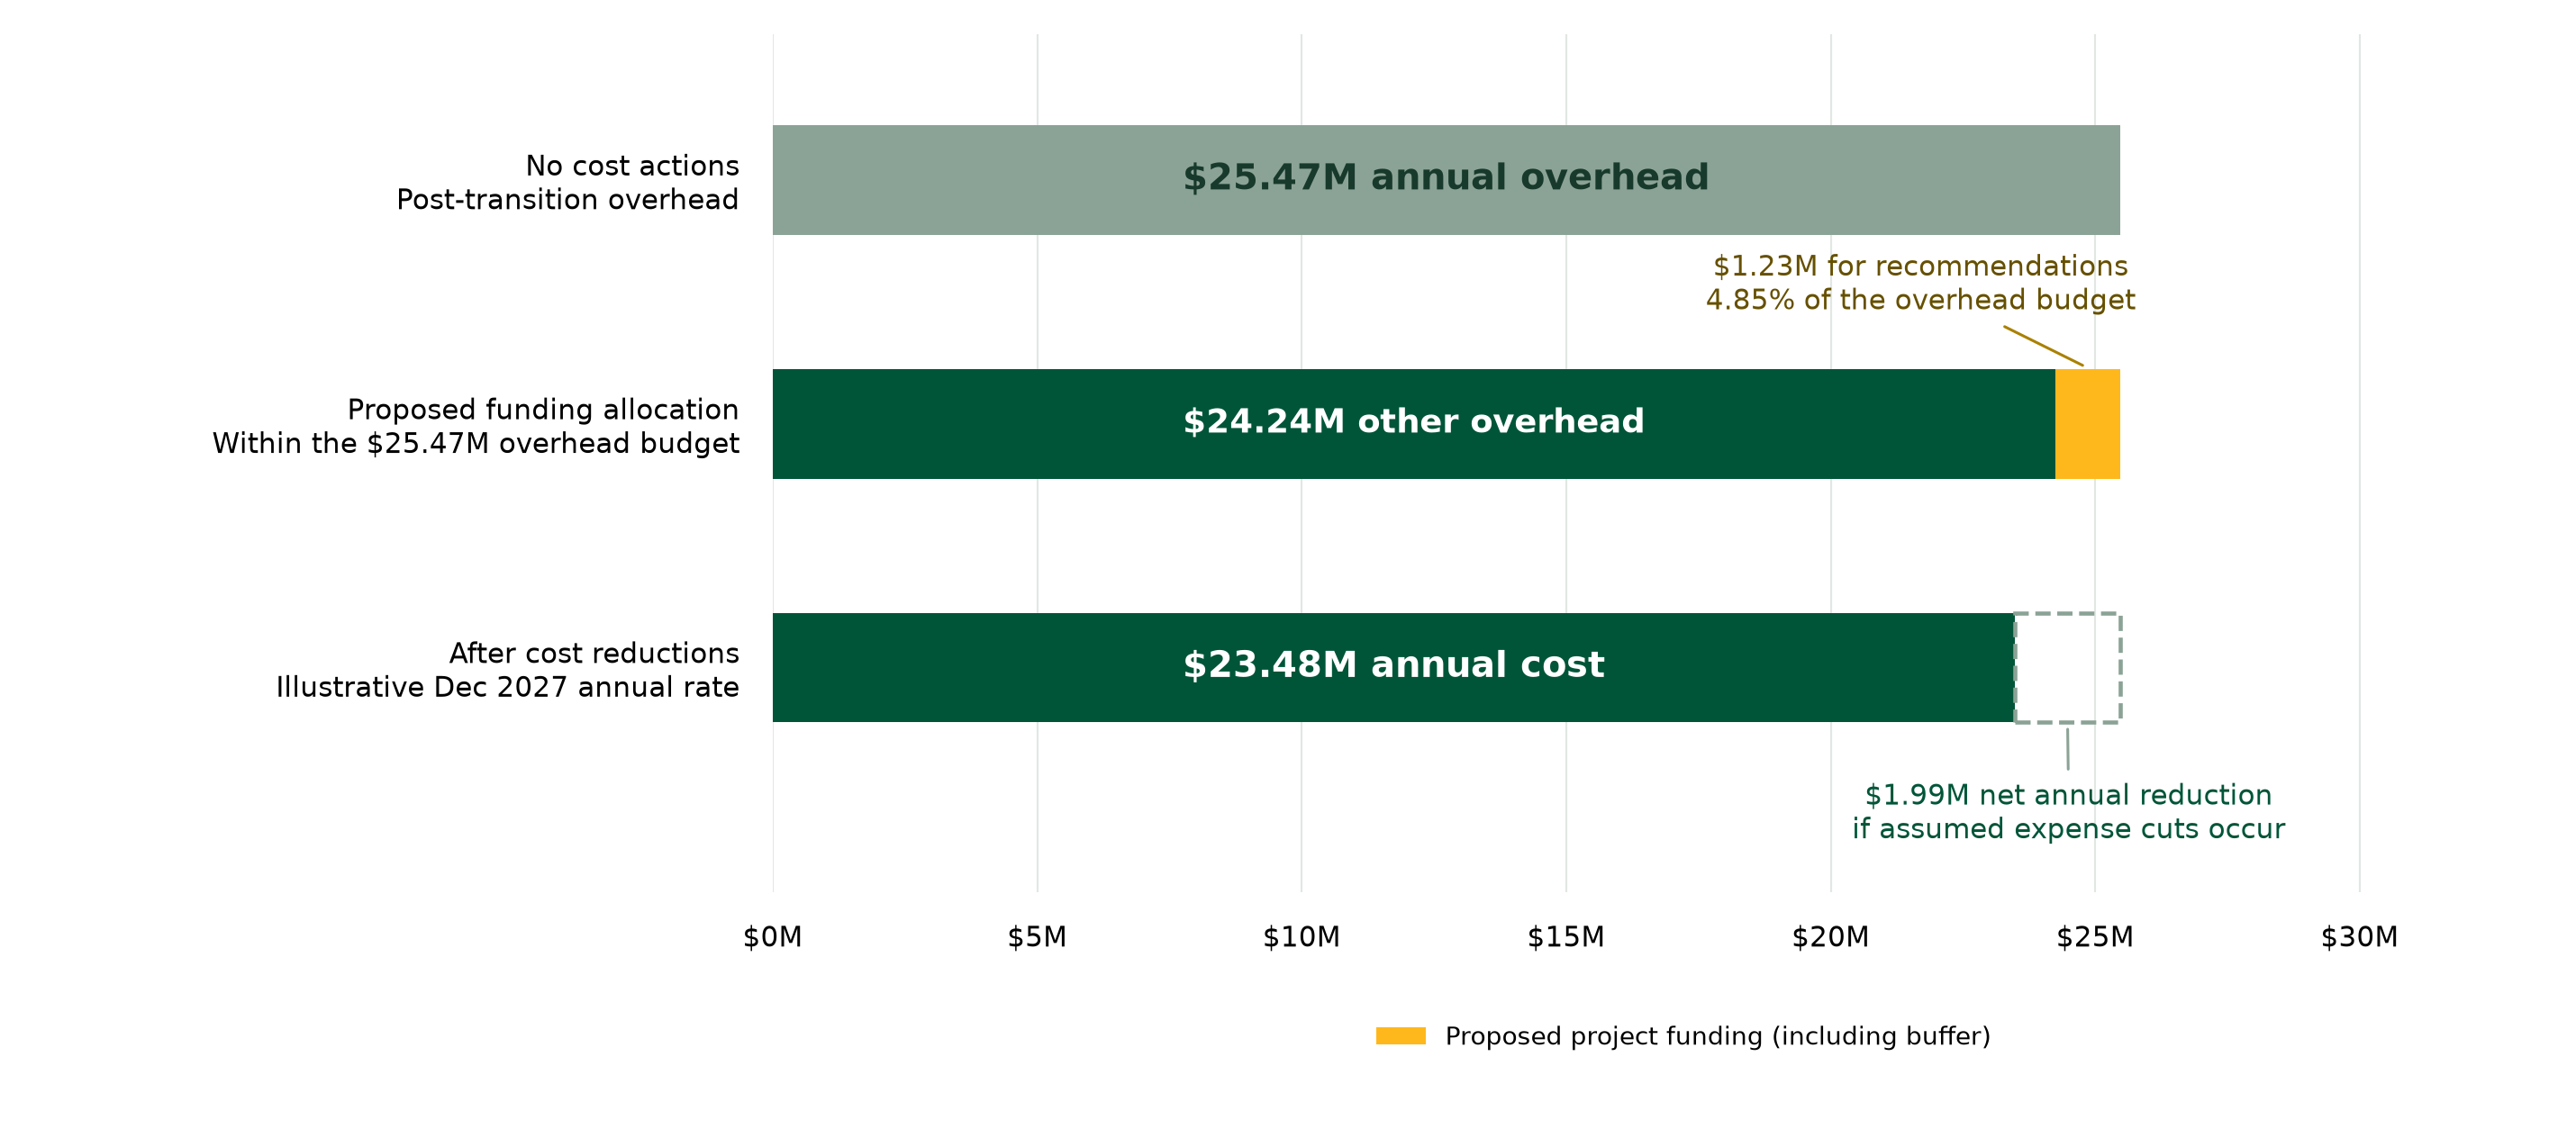

Annual expense cuts: $2,064,792
New annual recurring spending: $73,361
Net annual reduction: $1,991,432
Full 13-month implementation resources, including reserve: $4,269,652


In [1]:
from pathlib import Path
import math
from openpyxl import load_workbook
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from IPython.display import Image, display, Markdown

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis_outputs/recommendation_costs/IEHP_Simple_Transition_Budget.xlsx").is_file())
w = load_workbook(root / "analysis_outputs/recommendation_costs/IEHP_Simple_Transition_Budget.xlsx", data_only=True)
b, d, c = w["Simple Budget"], w["Sources and Costs"], w["Cash Savings"]
def num(sheet, address):
    v = sheet[address].value
    if isinstance(v, bool) or not isinstance(v, (int,float)) or not math.isfinite(v):
        raise ValueError(f"Recalculate Excel: {sheet.title}!{address}")
    return float(v)

# Editable post-implementation operating assumptions; not observed IEHP workload.
PROVIDER_HOURS_PER_YEAR = 974
MONITORING_HOURS_PER_YEAR = 672
baseline = num(b, "B11")
reuse = num(b, "B19")
ongoing_labor = PROVIDER_HOURS_PER_YEAR*num(d,"C17") + MONITORING_HOURS_PER_YEAR*num(d,"C21")
existing_reassigned = ongoing_labor*reuse
new_recurring = ongoing_labor*(1-reuse) + num(d,"D22") + num(d,"D23") + 12*num(d,"C24")
ongoing_resources = existing_reassigned + new_recurring
# Annual rate: do not use the prorated in-year cash-saving column G.
annual_removed = sum(num(c,f"C{r}")*num(c,f"D{r}") for r in [12,13,14])
# Show ALL implementation resources, not just continuing operations.
# Annualize the 13-month implementation budget for an equal-duration comparison.
PROJECT_MONTHS = 13
annualization = 12 / PROJECT_MONTHS
project_reassigned = num(b, "B27")
project_new = num(b, "B23")
project_reserve = num(b, "B25")
project_full = project_reassigned + project_new + project_reserve
allocated_staff = project_reassigned * annualization
allocated_new = project_new * annualization
allocated_reserve = project_reserve * annualization
allocated_total = allocated_staff + allocated_new + allocated_reserve
reallocation_total = baseline + allocated_new + allocated_reserve
final_total = baseline - annual_removed + new_recurring
net_reduction = baseline-final_total
assert 0 <= reuse <= 1
assert annual_removed + existing_reassigned < baseline
assert allocated_staff < baseline
assert math.isclose(reallocation_total, baseline-allocated_staff+allocated_total, abs_tol=.01)
w.close()

fig, ax = plt.subplots(figsize=(13,5.7))
green, muted, gold = "#005538", "#8BA396", "#FFB81C"
ax.barh(2, baseline/1e6, height=.45, color=muted, zorder=3)
# Proposed funding envelope, not a claim that expense has been eliminated.
funding_slice = project_new + project_reserve
other_overhead = baseline - funding_slice
reallocation_total = baseline
ax.barh(1, other_overhead/1e6, height=.45, color=green, zorder=3)
ax.barh(1, funding_slice/1e6, left=other_overhead/1e6, height=.45, color=gold, zorder=3)
ax.barh(0, final_total/1e6, height=.45, color=green, zorder=3)
if net_reduction > 0:
    ax.barh(0, net_reduction/1e6, left=final_total/1e6, height=.45,
            color="none", edgecolor="#8BA396", linestyle="--", linewidth=1.5, zorder=3)
for y,amount,color,label in [(2,baseline,"#173A2C","annual overhead"),(0,final_total,"white","annual cost")]:
    ax.text(amount/2e6,y,f"${amount/1e6:.2f}M {label}",ha="center",va="center",fontsize=13,weight="bold",color=color)
ax.text(other_overhead/2e6,1,f"${other_overhead/1e6:.2f}M other overhead",
        ha="center",va="center",fontsize=12,weight="bold",color="white")
ax.annotate(f"${funding_slice/1e6:.2f}M for recommendations\n{funding_slice/baseline:.2%} of the overhead budget",
            xy=((other_overhead+funding_slice/2)/1e6,1.23),xytext=(21.7,1.57),
            fontsize=10,ha="center",va="center",color="#665000",
            arrowprops={"arrowstyle":"-","color":"#AA8100","lw":1})
if net_reduction > 0:
    ax.annotate(f"${net_reduction/1e6:.2f}M net annual reduction\nif assumed expense cuts occur",
                xy=((final_total+baseline)/2e6,-.23),xytext=(24.5,-.60),
                fontsize=10,ha="center",va="center",color=green,
                arrowprops={"arrowstyle":"-","color":muted,"lw":1})
ax.set_yticks([2,1,0],["No cost actions\nPost-transition overhead","Proposed funding allocation\nWithin the $25.47M overhead budget","After cost reductions\nIllustrative Dec 2027 annual rate"])
ax.set_xlim(0,max(33,reallocation_total/1e6*1.3))
ax.set_ylim(-.92,2.6)
ax.set_xticks([0,5,10,15,20,25,30])
ax.xaxis.set_major_formatter(FuncFormatter(lambda x,_:f"${x:.0f}M"))
ax.tick_params(length=0,pad=12,labelsize=10)
ax.set_axisbelow(True)
ax.grid(axis="x",color="#E1E7E3",linewidth=.7)
for spine in ax.spines.values():spine.set_visible(False)
ax.legend(handles=[Patch(facecolor=gold,label="Proposed project funding (including buffer)")],
          loc="upper center",bbox_to_anchor=(.52,-.13),frameon=False,fontsize=9)
fig.subplots_adjust(left=.30,right=.98,top=.97,bottom=.21)
out=root/"analysis_outputs/slide_exports/financial_impact"
out.mkdir(parents=True,exist_ok=True)
for ext in ["png","svg","pdf"]:
    fig.savefig(out/f"IEHP_overhead_reallocation_impact.{ext}",dpi=220,facecolor="white")
plt.close(fig)
display(Image(filename=str(out/"IEHP_overhead_reallocation_impact.png"),embed=True,width=1200))

print(f"Annual expense cuts: ${annual_removed:,.0f}")
print(f"New annual recurring spending: ${new_recurring:,.0f}")
print(f"Net annual reduction: ${net_reduction:,.0f}")
print(f"Full 13-month implementation resources, including reserve: ${project_full:,.0f}")
